# Evaluate results of Beast run - Compare skygrid and constcoal prior for a SARS-CoV-2 Alpha VoC data set in the UK

In [5]:
import pandas as pd
import numpy as np

import re

import matplotlib.pyplot as plt
import seaborn as sns

import dendropy

from evaluation_helpers import *
from evaluation_helpers import _decimal_year_to_datetime

## Analyze inferred population trajectory and general tree statistics
- population trajectories
- fit of exponential growth rate on skygrid estimate
- constant-size population estimate and skygrid estimates 
- root height
- tree length

,median,hpd_lower,hpd_upper
skygrid,0.319887,0.281941,0.382704
constcoal,0.599826,0.479267,0.742717


30.51225005281164 23.6288066929115 39.60746936853828


<Axes: xlabel='Time (years)', ylabel='Effective Population Size'>

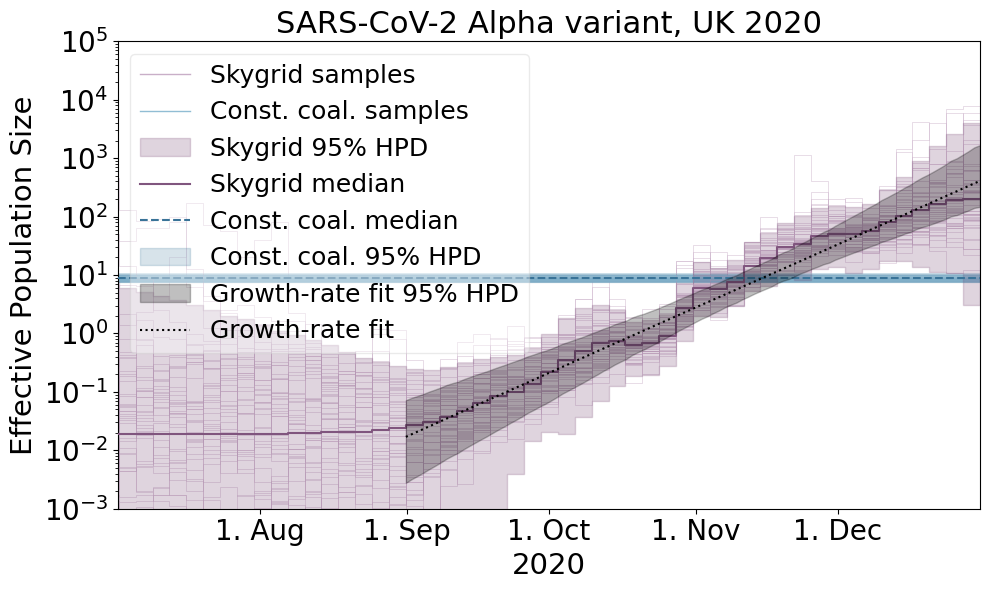

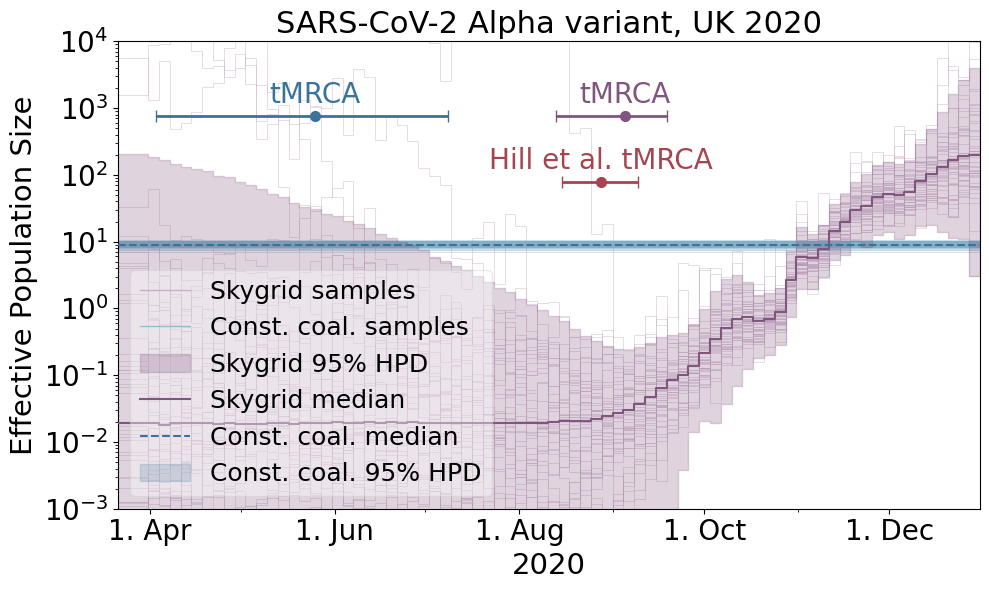

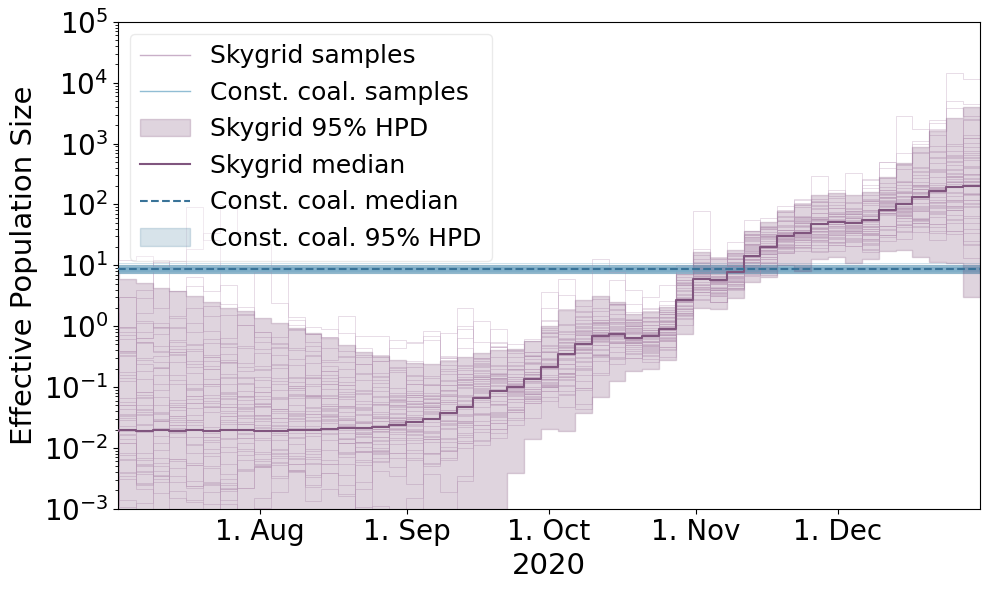

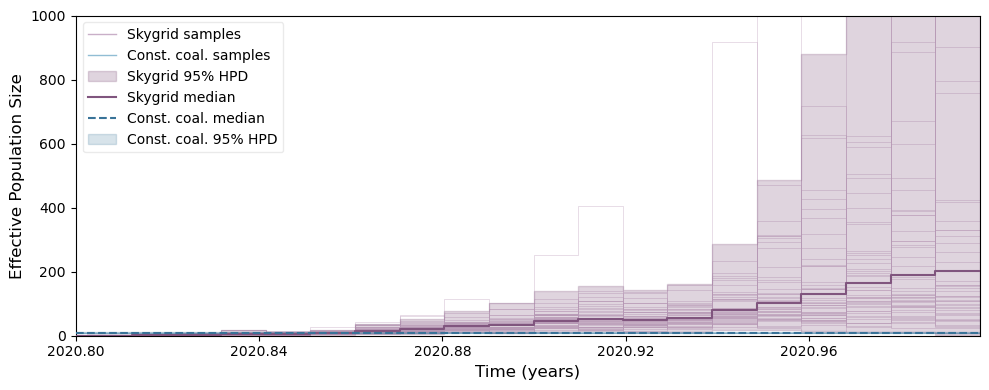

In [ ]:
skygrid_log = read_beast_log('data/sarscov/beast_skygrid/SG_b117_combined.log')
constcoal_log = read_beast_log('data/sarscov/beast_constcoal/SG_constant_b117_combined.log')

rootheight_df = compute_root_height_summary(skygrid_log, constcoal_log)
display(rootheight_df)

sky_summary = compute_skygrid_summary(skygrid_log, t_present=2020.9972677595629, end_time=2020, cutoff = 0.75, n_grid_points=77)
const_summary = compute_constcoal_summary(constcoal_log)

# the growth rate within the considered time window is a lot bigger than what we consider in the theory part
# could alternatively also see the flattening at the end not as part of the exponential growth and only fit until 01.12.
growth = fit_exponential_growth_rate(sky_summary, '2020-08-31', '2020-12-31')
print(growth['rate_median'], growth['rate_hpd_lower'], growth['rate_hpd_upper'])

# look at plots
plot_pertussis_skygrid(sky_summary, const_summary,title='SARS-CoV-2 Alpha variant, UK 2020', save_path='figures/sarscov_popsize_growthfit.pdf', x_label="2020",
                       fontsize=21, tick_fontsize=20, legend_fontsize=18, title_fontsize= 22, figsize=(10, 6), cutoff = 2020.5, y_range = (1e-3, 1e5), time_unit = 'dates',
                       growth_fit=growth,)
plot_pertussis_skygrid(sky_summary, const_summary, save_path='figures/sarscov_popsize.pdf', x_label="2020", root_height_summary=rootheight_df, title='SARS-CoV-2 Alpha variant, UK 2020',
                       fontsize=21, tick_fontsize=20, legend_fontsize=18, title_fontsize= 22, figsize=(10, 6), cutoff = 2020.22, y_range = (1e-3, 1e4), time_unit = 'dates', 
                       external_tmrca={'median': '2020-08-28', 'hpd_lower': '2020-08-15', 'hpd_upper': '2020-09-09', 'label': 'Hill et al. tMRCA',},)
plot_pertussis_skygrid(sky_summary, const_summary, title='', log_scale=False, y_range = (0, 1000), cutoff = 2020.8)

# Hill et al used an exponential-growth coalescent prior to infer the tmrca with BEAST v1.10.4

In [3]:
treelength_df = compute_root_height_summary(skygrid_log, constcoal_log, column = 'treeLength')
display(treelength_df)

,median,hpd_lower,hpd_upper
skygrid,63.056156,58.882006,67.222611
constcoal,68.836022,62.342030,75.639616


In [ ]:
# transform decimal years to calendar dates

t_present = sky_summary['boundaries'][0]  # most recent sampling date, decimal year

for model in rootheight_df.index:
    row = rootheight_df.loc[model]
    med = _decimal_year_to_datetime(t_present - row['median']).date()                                                                                                                          
    hi  = _decimal_year_to_datetime(t_present - row['hpd_lower']).date()  # older bound -> later calendar date is wrong; see note                                                                                     
    lo  = _decimal_year_to_datetime(t_present - row['hpd_upper']).date()
    print(model, '-> median:', med, '| 95% HPD:', lo, 'to', hi)

skygrid -> median: 2020-09-04 | 95% HPD: 2020-08-12 to 2020-09-18
constcoal -> median: 2020-05-25 | 95% HPD: 2020-04-03 to 2020-07-08


## Compute summary tree:

We obtain summary trees using _treeannotator_:

```
scripts/run_treeannotator.sh \
--skygrid-in   data/sarscov/beast_skygrid/SG_b117_combined.trees \
--skygrid-out  data/sarscov/beast_skygrid/SG_b117_summary.tree \
--constcoal-in  data/sarscov/beast_constcoal/SG_constant_b117_combined.trees \
--constcoal-out data/sarscov/beast_constcoal/SG_constant_b117_summary.tree \
--heights keep
```

<Axes: ylabel='Date'>

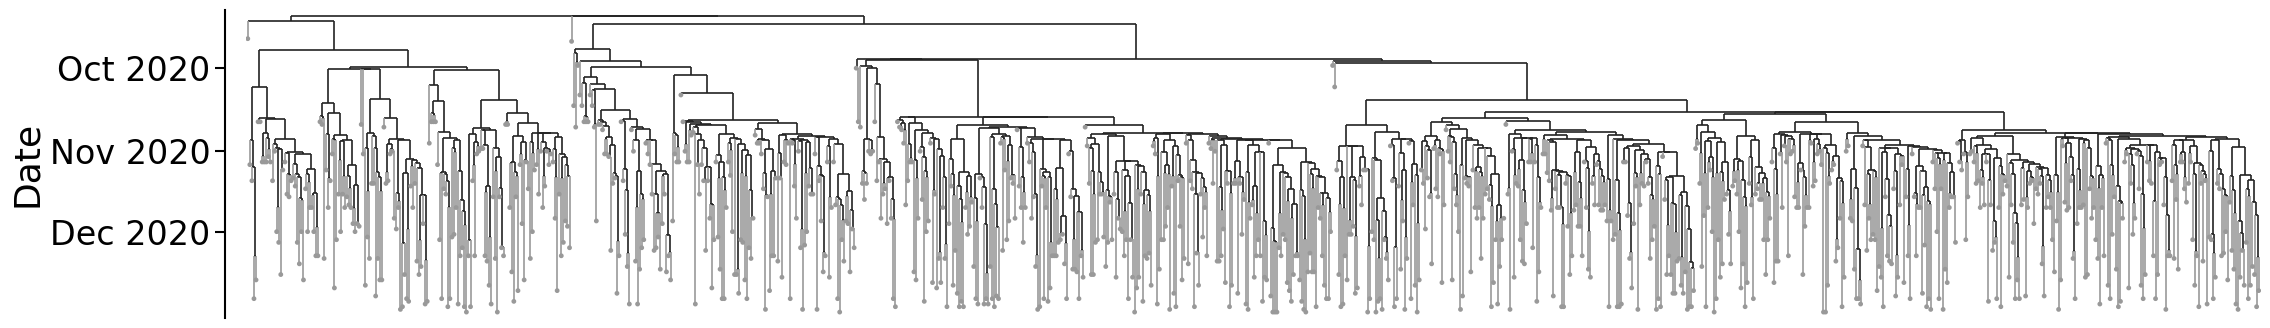

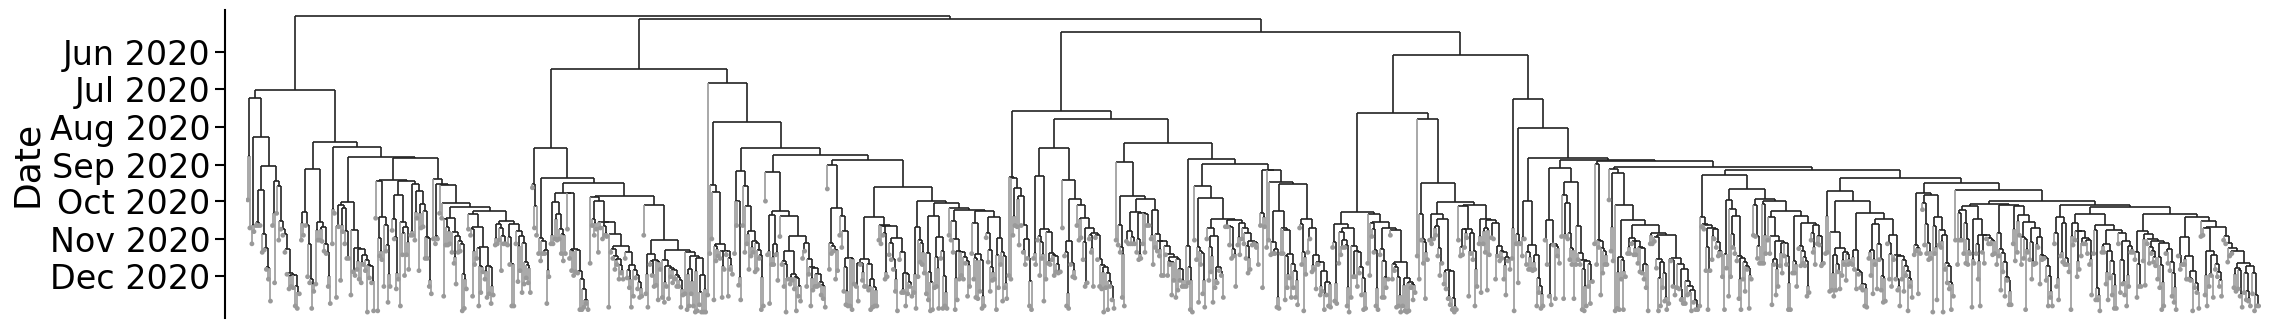

In [ ]:
# skygrid
plot_timetree(
    'data/sarscov/beast_skygrid/SG_b117_summary.tree',
    save_path='figures/sarscov2_timetree.pdf',
    color_branches = False,
    figsize=(26, 4)
  )

# constant-size coalescent
plot_timetree(
    'data/sarscov/beast_constcoal/SG_constant_b117_summary.tree',
    save_path='figures/sarscov2_timetree_constcoal.pdf',
    color_branches = False,
    figsize=(26, 4)
  )

## Compare tree topology
We compare the topology between trees inferred under the skygrid and constant-size coalescent prior, by plotting a tanglegram of the two summary trees. Coloring is done using _phyclip_ clusters as well as by sampling date.

<Axes: >

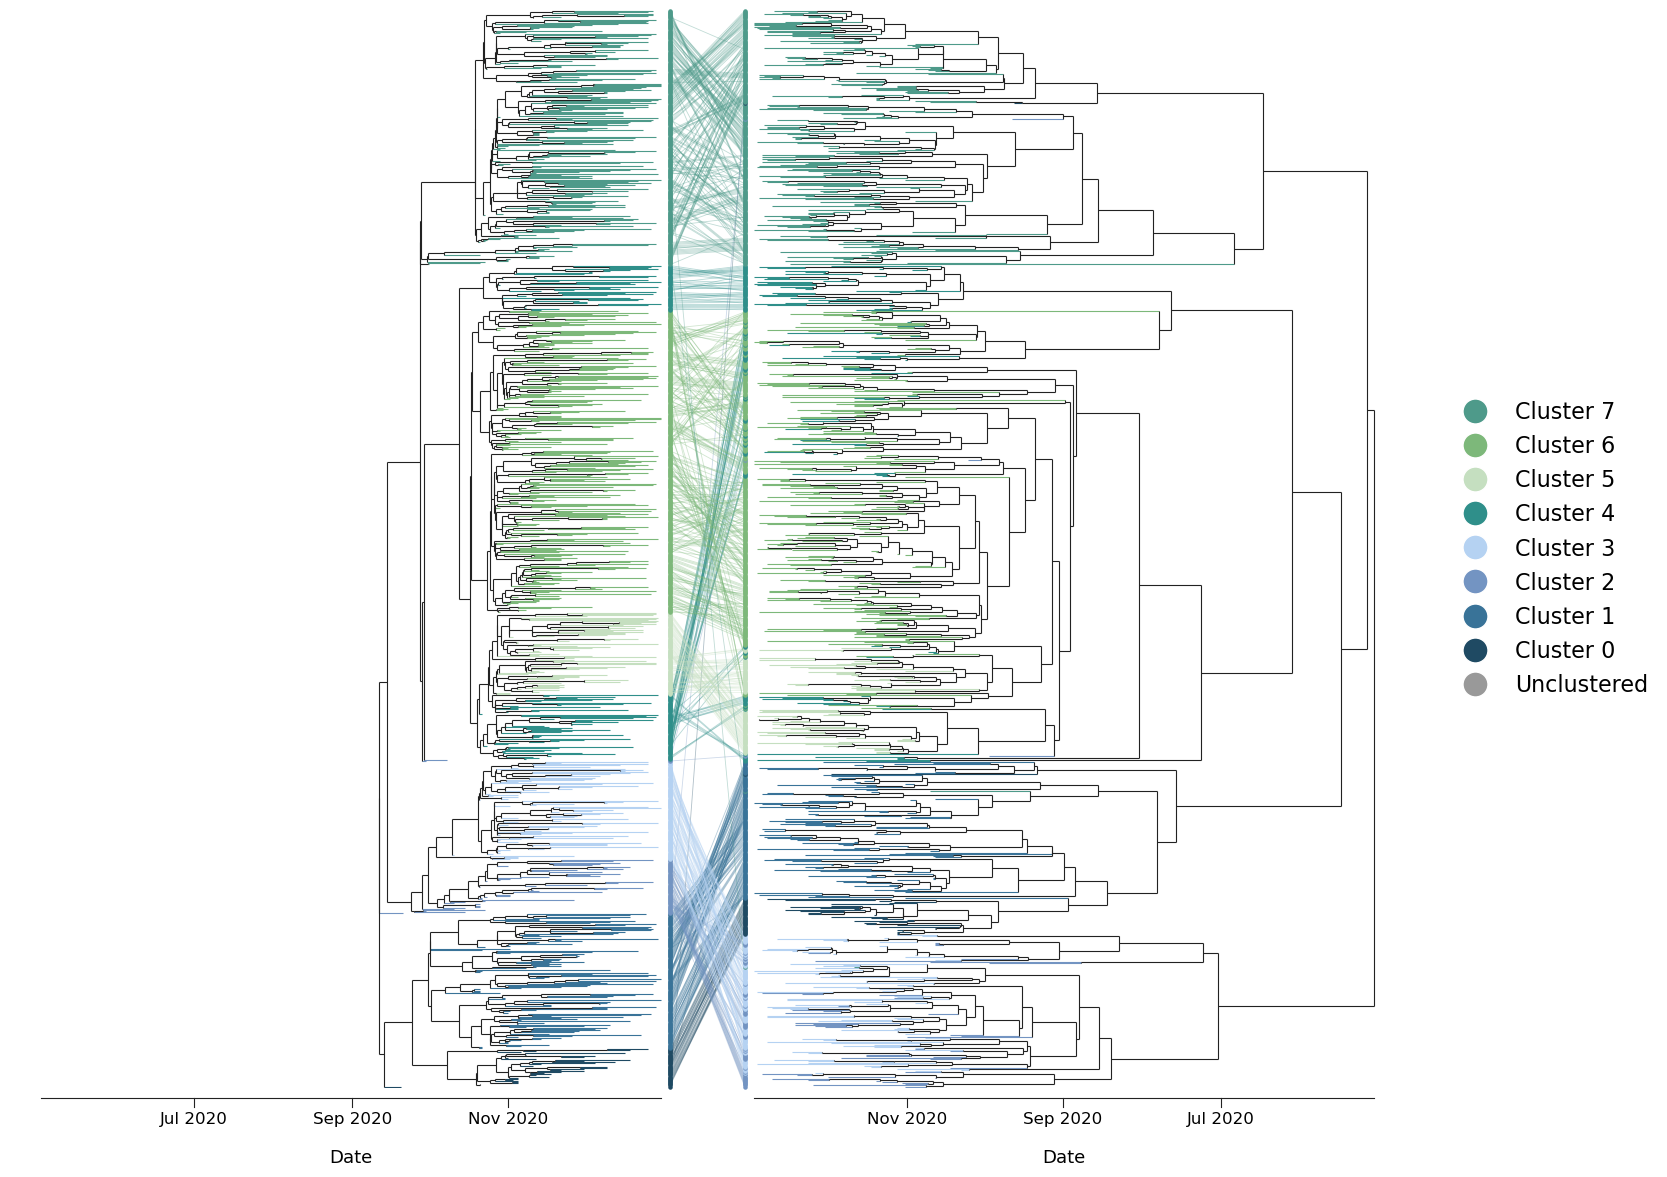

In [10]:
plot_tanglegram(
      'data/sarscov/beast_skygrid/SG_b117_summary.tree',
      'data/sarscov/beast_constcoal/SG_constant_b117_summary.tree',
      cluster_path='data/sarscov/phyclip/cluster_qn_kuiper_cs30_fdr0.05_gam7.0_sol0_f0_skygrid.txt',
      color_branches=False,
      sort_left_by_date=True,
      color_tips_by_date=False,
      save_path='figures/sarscov_tanglegram_clustered8.pdf',
  )

<Axes: >

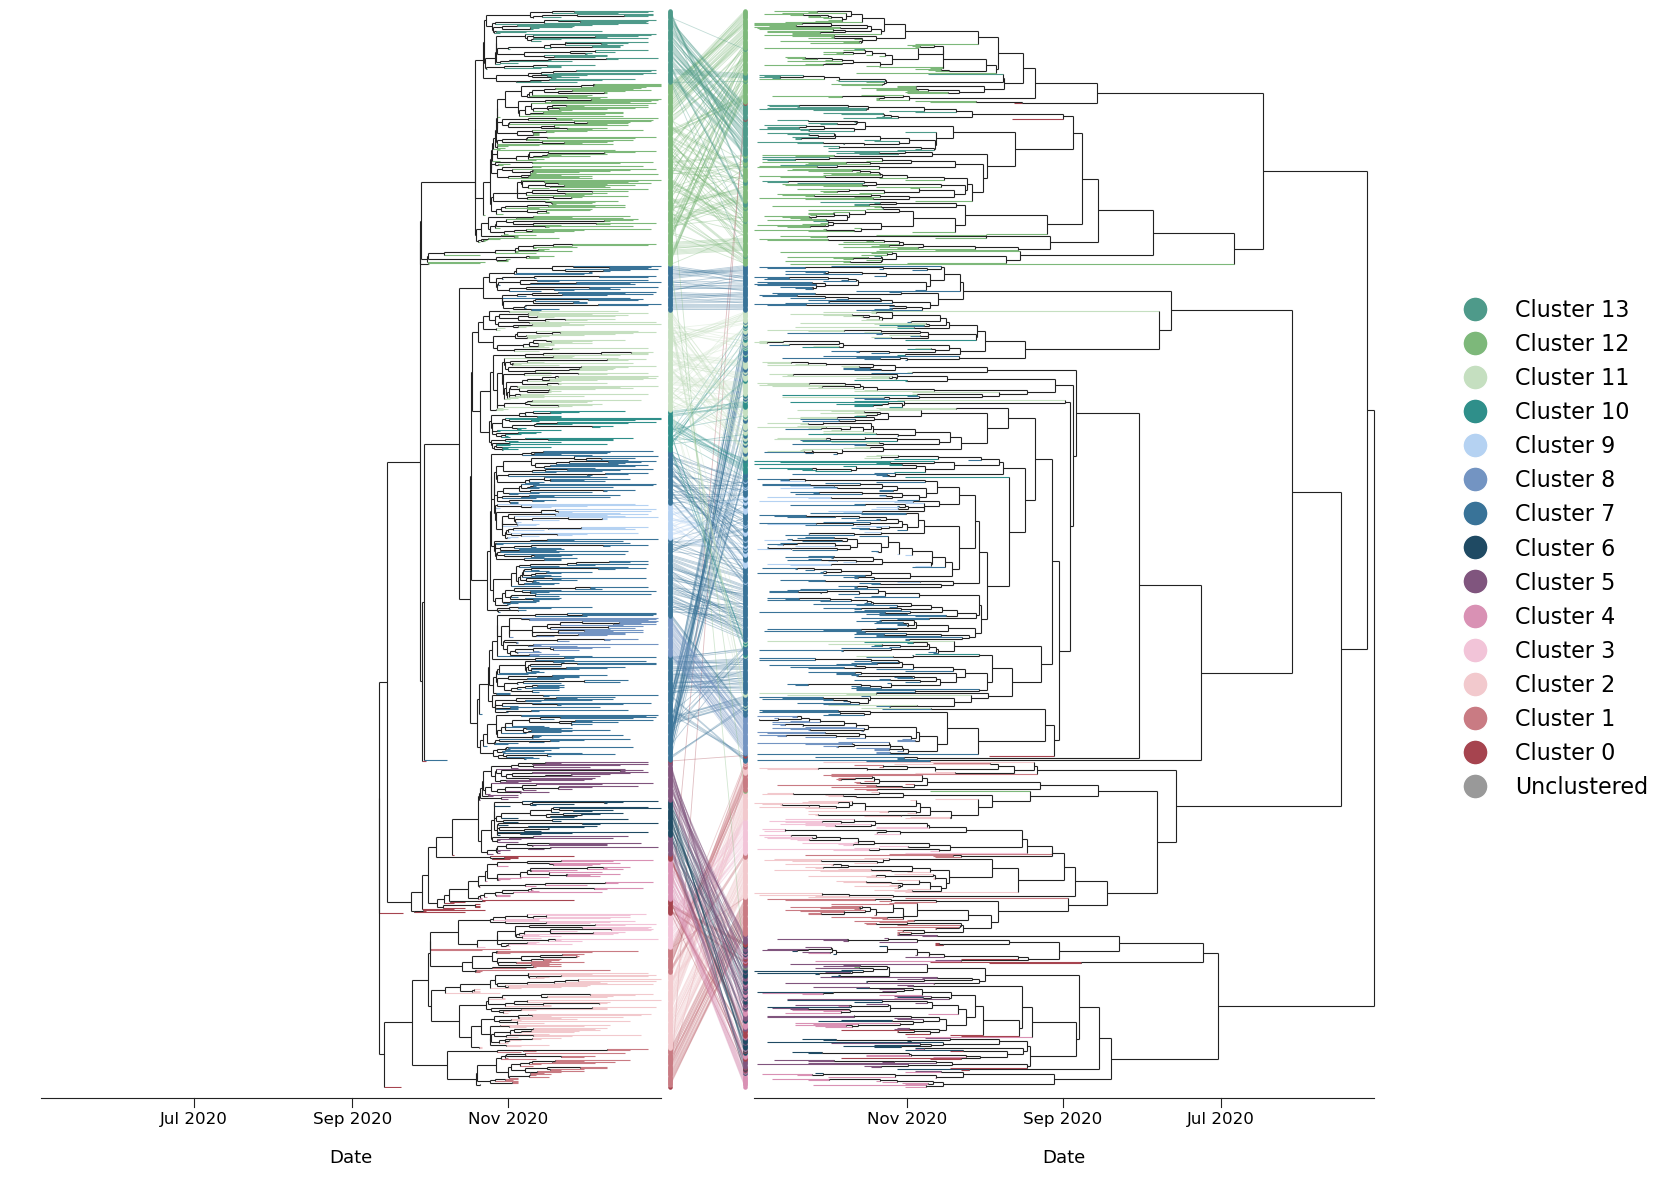

In [11]:
plot_tanglegram(
      'data/sarscov/beast_skygrid/SG_b117_summary.tree',
      'data/sarscov/beast_constcoal/SG_constant_b117_summary.tree',
      cluster_path='data/sarscov/phyclip/cluster_qn_kuiper_cs20_fdr0.05_gam5.0_sol0_f0_skygrid.txt',
      color_branches=False,
      sort_left_by_date=True,
      color_tips_by_date=False,
      save_path='figures/sarscov_tanglegram_clustered14.pdf',
  )

/Users/mariebecker/Documents/Uni/ETH/RotationStadler/coalescentpriorimpact_part3_data/evaluation_helpers.py:1996: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels([datetime.fromordinal(int(t)).strftime('%Y-%m-%d') for t in ticks])


<Axes: >

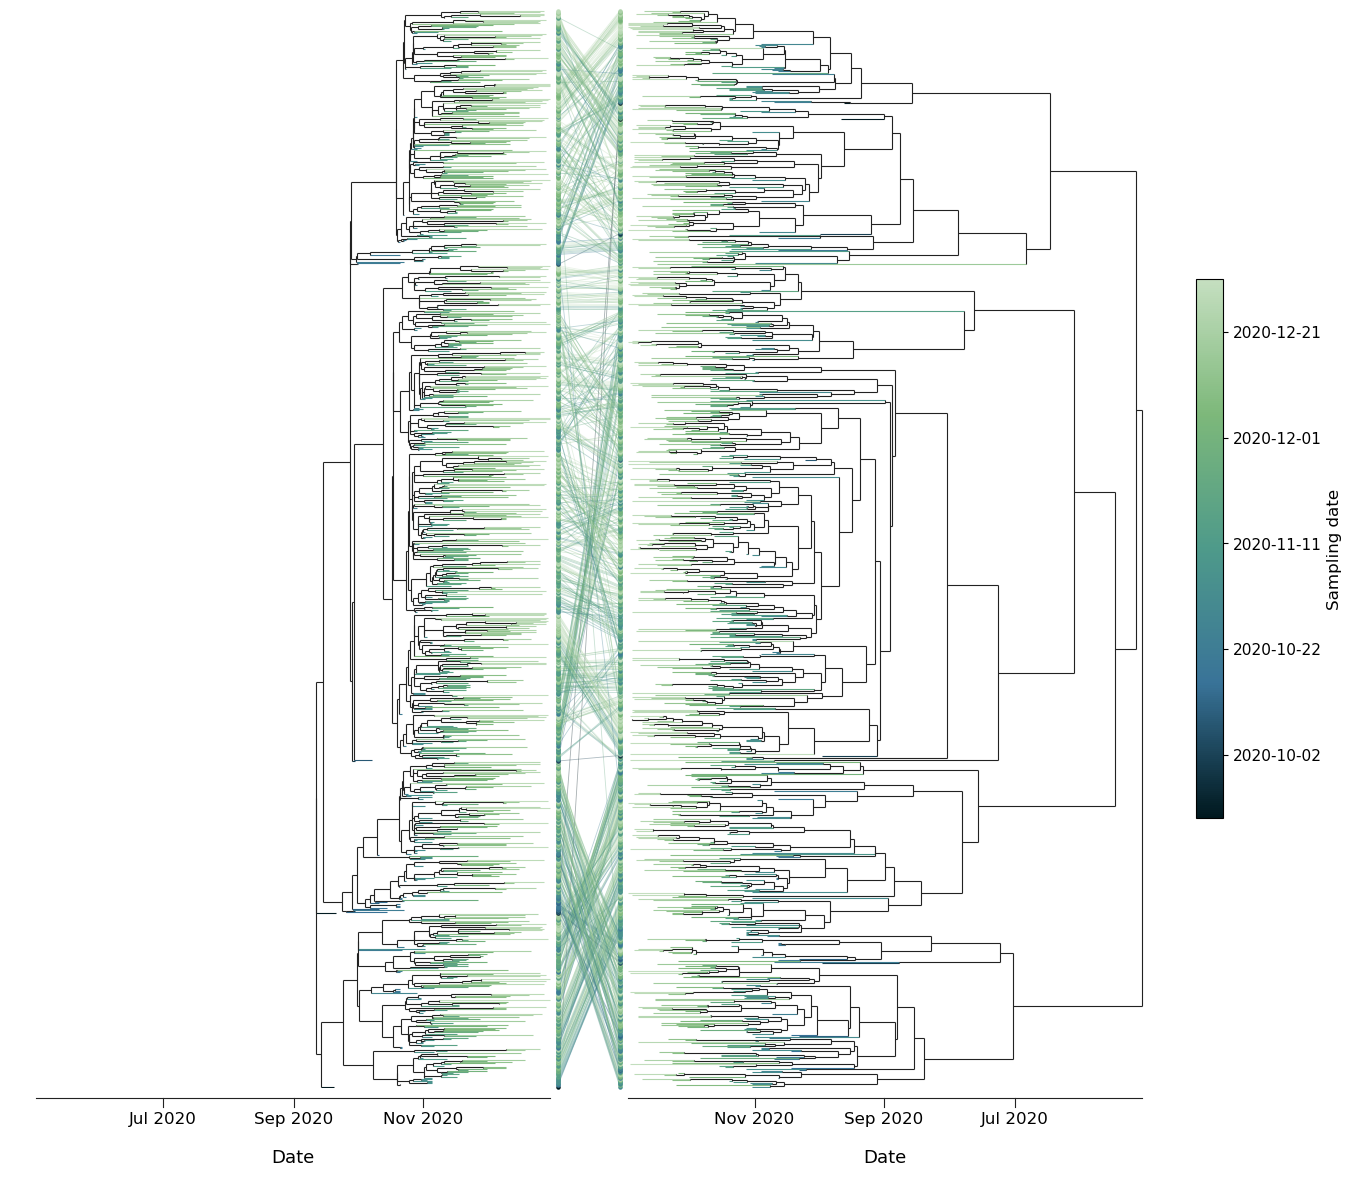

In [12]:
plot_tanglegram(
    'data/sarscov/beast_skygrid/SG_b117_summary.tree',
    'data/sarscov/beast_constcoal/SG_constant_b117_summary.tree',
    color_branches=False,
    sort_left_by_date=True,
    color_tips_by_date=True,
    save_path='figures/sarscov_tanglegram_samplingdates.pdf',
)

We next compare topologies by considering the Robinson Foulds Distance: How many internal branch-induced splits are shared or not shared between two trees. The maximal distance is 2 * (n - 3) where n - 3 is the number of internal splits exluding the root and trivial leaf splits (2 * because in case of a missplit, both trees would be split wrongly).

Robinson foulds distances are calculated with `sbatch scripts/run_topology_distances.sh` which runs `scripts/compute_topology_distances.py`.

```
sbatch scripts/run_topology_distances.sh \
data/sarscov/beast_skygrid/SG_b117_combined.subsampled1000.trees \
data/sarscov/beast_constcoal/SG_constant_b117_combined.subsampled1000.trees \
data/sarscov/topology_distances_1000.csv
```

                      count      mean       std       min       25%       50%  \
comparison                                                                      
between           1027000.0  0.772986  0.006727  0.735868  0.768756  0.772867   
within_constcoal   499500.0  0.761079  0.007330  0.726619  0.756423  0.761562   
within_skygrid     526851.0  0.775479  0.006555  0.739979  0.770812  0.775951   

                       75%       max  
comparison                            
between           0.778006  0.801644  
within_constcoal  0.765673  0.794450  
within_skygrid    0.780062  0.805755  


<Axes: xlabel='Normalised RF distance', ylabel='Density'>

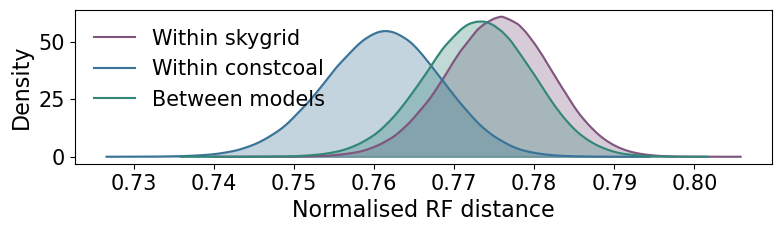

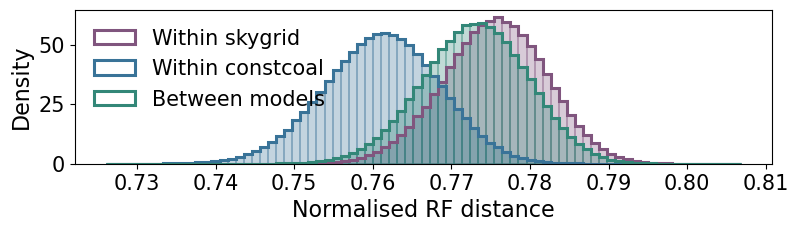

In [13]:
topology_dist_df = pd.read_csv('data/sarscov/topology_distances_1000.csv')
print(topology_dist_df.groupby('comparison')['rf_norm'].describe())

plot_rf_distributions(topology_dist_df, bw_method = 0.1, normalized=True, save_path='figures/rf_distributions_sarscov2_density.pdf', figsize=(9, 2), tick_fontsize= 15, legend_fontsize=15, fontsize= 16)
plot_rf_distributions(topology_dist_df, mode = 'hist', normalized=True, save_path='figures/rf_distributions_sarscov2_hist.pdf', figsize=(9, 2), tick_fontsize= 15, legend_fontsize=15, fontsize= 16)

# Compare pairwise tip-to-MRCA distances

We consider more detailed changes in tree dating by considering pairwise tip-to-MRCA distances for a subset of 1000 posterior sample trees. For each possible tip pair, we consider their time to their MRCA over all posterior samples and obtain medians and HPD intervals. Results are obtained by running `scripts/compute_coalescent_distances.py` with `scripts/run_coalescent_distances.sh`:
```
sbatch scripts/run_coalescent_distances.sh \
data/sarscov/beast_skygrid/SG_b117_combined.subsampled1000.trees \
data/sarscov/beast_constcoal/SG_constant_b117_combined.subsampled1000.trees \
data/sarscov/taxon_dates.tsv \
data/sarscov/coalescent_tip_distances_1000.tsv
```

We consider tips sampled after 15. November 2020 were the constant-size coalescent prior population size estimates are higher compared to the skyline prior and before that date where they are lower.

In [14]:
coalescent_tip_dist = pd.read_csv("data/sarscov/coalescent_tip_distances_1000.tsv", sep = "\t",)
coalescent_tip_dist.head()

,tip1,tip2,tip1_date,tip2_date,skygrid_tip1_to_mrca_median,skygrid_tip1_to_mrca_hpd_lower,skygrid_tip1_to_mrca_hpd_upper,skygrid_tip2_to_mrca_median,skygrid_tip2_to_mrca_hpd_lower,skygrid_tip2_to_mrca_hpd_upper,...,abs_diff_tip1_hpd_upper,rel_diff_tip1_median,rel_diff_tip1_hpd_lower,rel_diff_tip1_hpd_upper,abs_diff_tip2_median,abs_diff_tip2_hpd_lower,abs_diff_tip2_hpd_upper,rel_diff_tip2_median,rel_diff_tip2_hpd_lower,rel_diff_tip2_hpd_upper
0,England/ALDP-B1F74A/2020|2020-11-02,England/ALDP-B46908/2020|2020-11-06,2020.836066,2020.846995,0.086418,0.051403,0.119810,0.097347,0.062332,0.130739,...,0.310779,1.932761,0.305263,4.268699,0.166375,0.049026,0.310779,1.710607,0.216359,3.615776
1,England/ALDP-B1F74A/2020|2020-11-02,England/ALDP-B5B180/2020|2020-11-08,2020.836066,2020.852459,0.140677,0.098427,0.194174,0.157071,0.114821,0.210568,...,0.421623,1.917148,0.620107,3.357771,0.270967,0.139173,0.421623,1.700975,0.634881,2.989484
2,England/ALDP-B1F74A/2020|2020-11-02,England/ALDP-B5C7C9/2020|2020-11-08,2020.836066,2020.852459,0.131617,0.085649,0.196339,0.148011,0.102043,0.212733,...,0.411597,1.963716,0.533448,3.889166,0.258318,0.111154,0.411597,1.741760,0.487823,3.292621
3,England/ALDP-B1F74A/2020|2020-11-02,England/ALDP-B61FC9/2020|2020-11-08,2020.836066,2020.852459,0.140677,0.098427,0.194174,0.157071,0.114821,0.210568,...,0.421623,1.917148,0.620107,3.357771,0.270967,0.139173,0.421623,1.700975,0.634881,2.989484
4,England/ALDP-B1F74A/2020|2020-11-02,England/ALDP-B748B9/2020|2020-11-12,2020.836066,2020.863388,0.131644,0.086163,0.194068,0.158966,0.113485,0.221391,...,0.410797,1.973131,0.395578,3.684549,0.256771,0.111154,0.410797,1.632010,0.471438,2.995500


(<Axes: ylabel='Const. coal.'>, <Axes: xlabel='Skygrid', ylabel='Rel. diff.'>)

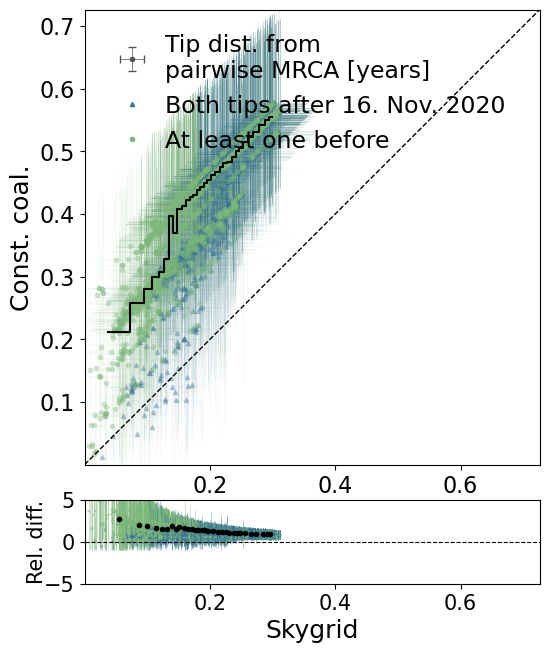

In [15]:
plot_pairwise_distances(coalescent_tip_dist, x_label = "Skygrid", ax=None, title="", n_subsample=5000, n_subsample_zoom=None, log_scale = False,
                        diff_plot = True, diff_mode='relative', diff_axis_range=(-5,5), color_threshold_date='2020-11-16',
                        point_alpha = 0.3, errorbar_alpha = 0.05, markersize=3, elinewidth=0.5, axis_range = None, zoom_range = None,
                        save_path = "figures/pairwise_tip_distances_reldiff_sarscov2.pdf", fontsize = 18,
                        running_avg = True, window_size = 30000, window_overlap = 0, window_size_zoom = None, window_overlap_zoom=None, running_avg_style='steps', running_avg_color = "black")